# CONTRÔLE CONTINU — PARTIE B
## Sujet 9 : Régimes de marché

### Problématique
Les régimes de stress détectés sans supervision
coïncident-ils avec la récession NBER de 2020
et avec les événements de marché documentés ?

**Algorithme principal :** Classification hiérarchique (Ward)
**Algorithme alternatif :** K-means
**Données :** S&P 500

In [3]:
# Importation des bibliothèques
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

# Configuration
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100

print("Bibliothèques importées avec succès !")

Bibliothèques importées avec succès !


In [4]:

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
chemin_fichier = '/content/drive/MyDrive/DS-F9-FADAL DIAE EDDINE- SAMI IKRAM-FIN2-2026/SP500 (1).csv'
df = pd.read_csv(chemin_fichier)

In [8]:
display(df.head())
print("Dimensions de la base :", df.shape)

,observation_date,SP500
0,2016-11-07,2131.52
1,2016-11-08,2139.56
2,2016-11-09,2163.26
3,2016-11-10,2167.48
4,2016-11-11,2164.45


Dimensions de la base : (2609, 2)


In [10]:
#NETTOYAGE DES DONNEES
# Conversion des dates
df['observation_date'] = pd.to_datetime(
    df['observation_date'],
    errors='coerce'
)

# Conversion des cours en valeurs numériques
df['SP500'] = pd.to_numeric(
    df['SP500'],
    errors='coerce'
)

# Suppression des dates invalides
df = df.dropna(subset=['observation_date'])

# Tri chronologique
df = df.sort_values('observation_date')

# Suppression des dates dupliquées
df = df.drop_duplicates(
    subset=['observation_date'],
    keep='last'
)

# Suppression des cours manquants ou non positifs
df = df.dropna(subset=['SP500'])
df = df[df['SP500'] > 0].copy()

df = df.reset_index(drop=True)

print("Dimensions après nettoyage :", df.shape)
print("Valeurs manquantes restantes :")
print(df.isnull().sum())


Dimensions après nettoyage : (2513, 2)
Valeurs manquantes restantes :
observation_date    0
SP500               0
dtype: int64


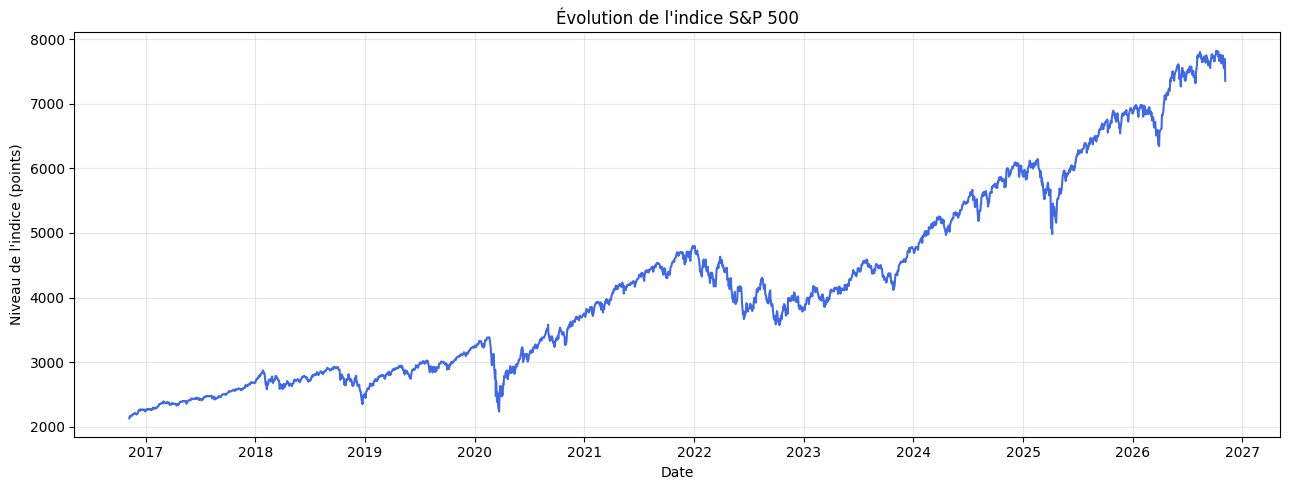

In [14]:
# Graphique 1 : évolution du S&P 500
plt.figure(figsize=(13, 5))

plt.plot(
    df['observation_date'],
    df['SP500'],
    color='royalblue',
    linewidth=1.5
)

plt.title("Évolution de l'indice S&P 500")
plt.xlabel("Date")
plt.ylabel("Niveau de l'indice (points)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


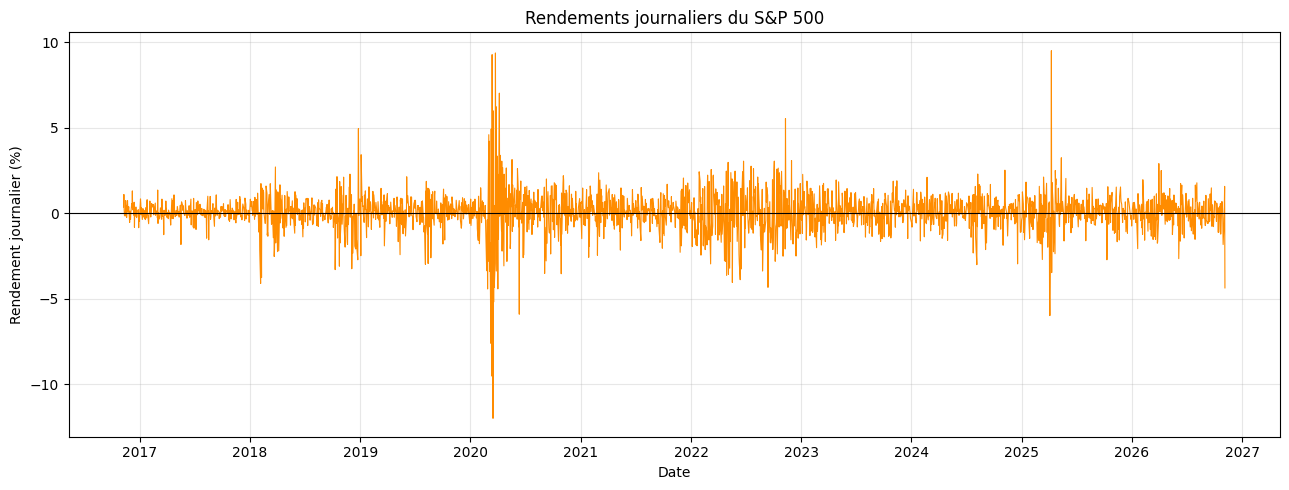

In [15]:
#Graphique 2 : rendements journaliers
df['rendement_journalier'] = df['SP500'].pct_change()

plt.figure(figsize=(13, 5))

plt.plot(
    df['observation_date'],
    df['rendement_journalier'] * 100,
    color='darkorange',
    linewidth=0.8
)

plt.axhline(0, color='black', linewidth=0.8)

plt.title("Rendements journaliers du S&P 500")
plt.xlabel("Date")
plt.ylabel("Rendement journalier (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


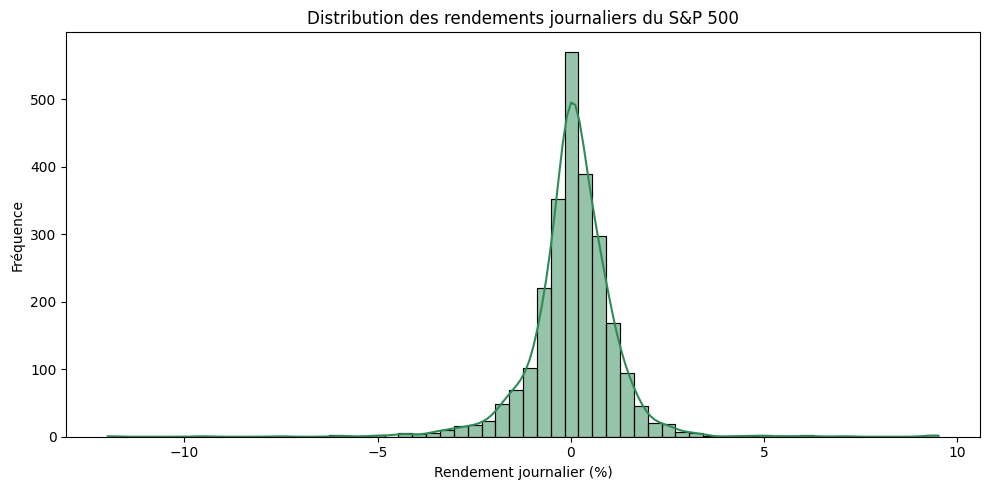

In [16]:
#Graphique 3 : distribution des rendements
plt.figure(figsize=(10, 5))

sns.histplot(
    df['rendement_journalier'].dropna() * 100,
    bins=60,
    kde=True,
    color='seagreen'
)

plt.title("Distribution des rendements journaliers du S&P 500")
plt.xlabel("Rendement journalier (%)")
plt.ylabel("Fréquence")
plt.tight_layout()
plt.show()


In [17]:
#Étape 6 — Création des trois variables financières
# Rendement journalier
df['rendement_journalier'] = df['SP500'].pct_change()

# Volatilité annualisée sur 21 jours
df['volatilite_21j'] = (
    df['rendement_journalier']
    .rolling(21)
    .std() * np.sqrt(252)
)

# Plus haut des 21 dernières séances
df['plus_haut_21j'] = (
    df['SP500'].rolling(21).max()
)

# Drawdown
df['drawdown'] = (
    df['SP500'] / df['plus_haut_21j'] - 1
)

# Rendement cumulé sur 21 séances
df['rendement_cumule_21j'] = (
    df['SP500'] / df['SP500'].shift(21) - 1
)

# Suppression des observations incomplètes
df = df.dropna(
    subset=[
        'volatilite_21j',
        'drawdown',
        'rendement_cumule_21j'
    ]
).copy()

df = df.reset_index(drop=True)

display(
    df[['observation_date', 'SP500',
        'volatilite_21j', 'drawdown',
        'rendement_cumule_21j']].head()
)


,observation_date,SP500,volatilite_21j,drawdown,rendement_cumule_21j
0,2016-12-07,2241.35,0.075403,0.000000,0.051527
1,2016-12-08,2246.19,0.075241,0.000000,0.049837
2,2016-12-09,2259.53,0.069609,0.000000,0.044502
3,2016-12-12,2256.96,0.070500,-0.001137,0.041283
4,2016-12-13,2271.72,0.071128,0.000000,0.049560


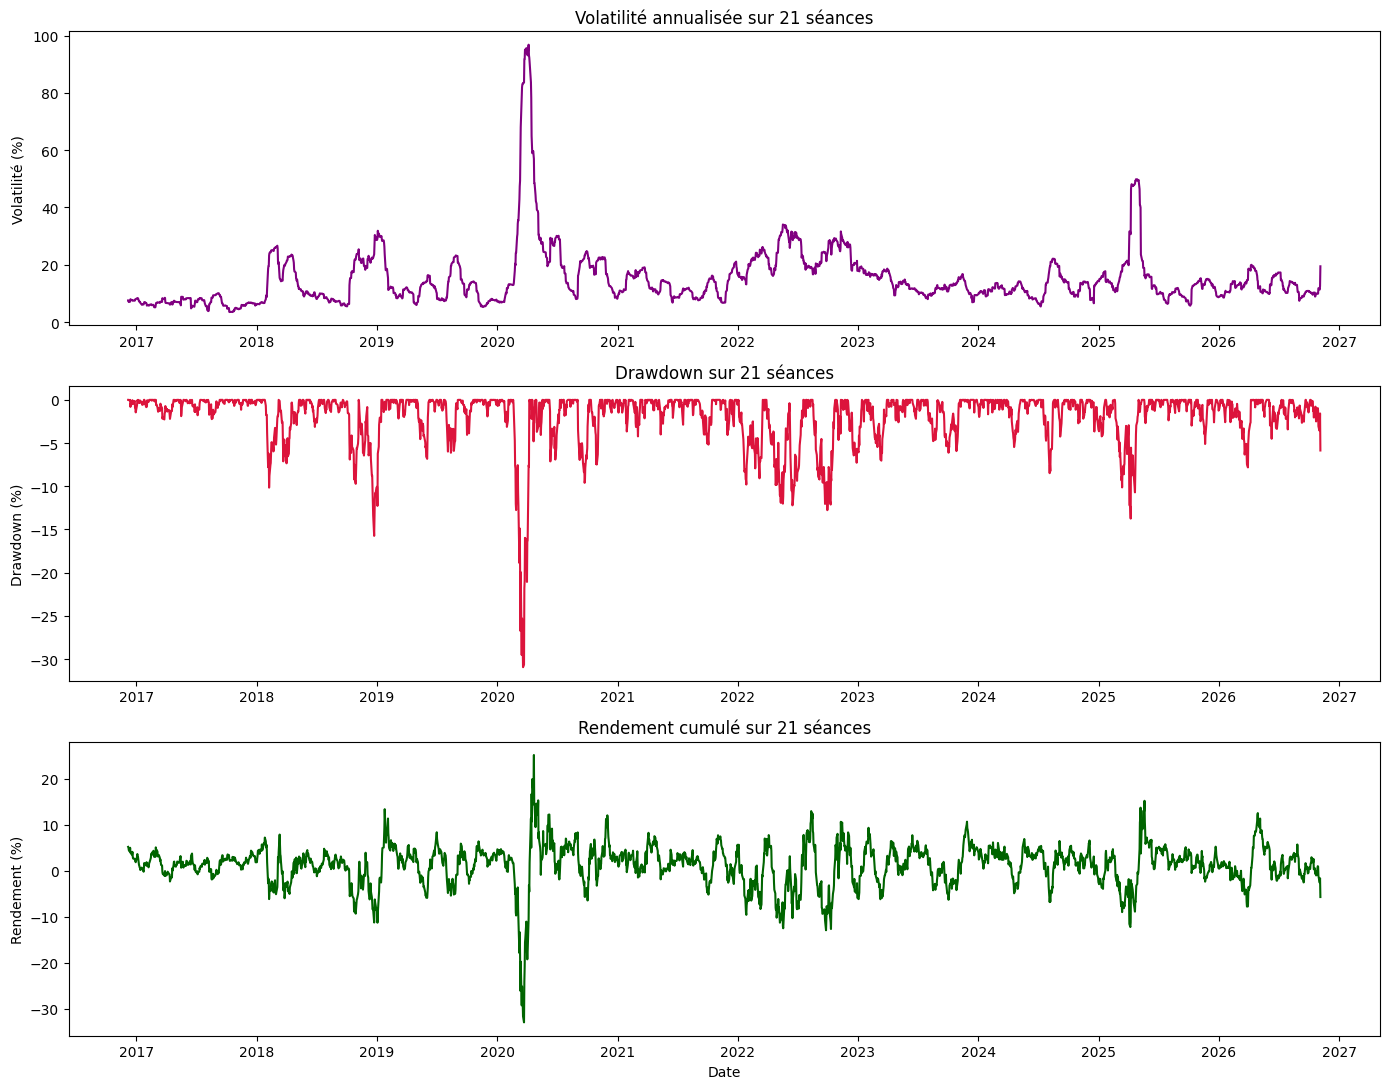

In [18]:
#Étape 7 — Visualisation des variables financières
fig, axes = plt.subplots(3, 1, figsize=(14, 11))

axes[0].plot(
    df['observation_date'],
    df['volatilite_21j'] * 100,
    color='purple'
)
axes[0].set_title("Volatilité annualisée sur 21 séances")
axes[0].set_ylabel("Volatilité (%)")

axes[1].plot(
    df['observation_date'],
    df['drawdown'] * 100,
    color='crimson'
)
axes[1].set_title("Drawdown sur 21 séances")
axes[1].set_ylabel("Drawdown (%)")

axes[2].plot(
    df['observation_date'],
    df['rendement_cumule_21j'] * 100,
    color='darkgreen'
)
axes[2].set_title("Rendement cumulé sur 21 séances")
axes[2].set_ylabel("Rendement (%)")
axes[2].set_xlabel("Date")

plt.tight_layout()
plt.show()


In [19]:

# Définition des variables utilisées
features = [
    'volatilite_21j',
    'drawdown',
    'rendement_cumule_21j'
]

# Entraînement : avant 2019
train = df[
    df['observation_date'] < '2019-01-01'
].copy()

# Validation : année 2019
valid = df[
    (df['observation_date'] >= '2019-01-01') &
    (df['observation_date'] < '2020-01-01')
].copy()

# Test : à partir de 2020
test = df[
    df['observation_date'] >= '2020-01-01'
].copy()

print("Entraînement :", train.shape)
print("Validation :", valid.shape)
print("Test :", test.shape)


Entraînement : (519, 7)
Validation : (252, 7)
Test : (1721, 7)
